# 04. Кандидатогенерация и отбор топ-50

Схема решения:

```
запрос ──► 1. источники сигнала (по всем ~195 тыс. объявлений)
             • BM25 по полям: заголовок / вид+тип+услуги / параметры / описание (стемминг Snowball)
             • TF-IDF по символьным 3–5-граммам (опечатки, части слов)
             • дообученные e5-base и e5-large (смысл, синонимы)             ← 03_dense
             • классификатор микрокатегории по тексту запроса
             • гео-приор: P(локация объявления | локация поиска), выучен по train
        ──► 2. каналы = текстовый скор + вес·гео; из каждого канала топ-K → пул ~1000 кандидатов
        ──► 3. LightGBM (lambdarank) по ~45 признакам ранжирует пул → топ-50 в answer.csv
```

Почему так:

* **Несколько каналов**: каждый ловит свои случаи (EDA: 92% пар находятся по словам, остальным нужна семантика;
  опечатки ловят n-граммы). Recall пула — потолок качества, поэтому каналы подбираются на полноту.
* **Гео в каждом канале**: 83% выборов — в той же локации. Без гео лучшее по тексту объявление из другого города
  вытесняет нужное.
* **Ранжировщик**: объединяет сигналы лучше ручных весов и учитывает фильтры запроса (совпадение «Вид услуги» — 98.4%)
  и «привлекательность» объявления (отзывы, рейтинг).
* **Честная оценка**: ранжировщик обучается и оценивается на отложенных поисках (`02_prepare`) через 5-fold
  кросс-валидацию по запросам. Ни одна модель-источник эти поиски не видела.

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sys.path.insert(0, '..')
from src.pipeline import load_artifacts, build_sources, load_dense, build_pools, ART
from src.ranking import pool_recall, recall_by_score, cv_ranker, fit_ranker, make_answer, check_answer, feature_cols
sns.set_theme(style='whitegrid')

# e5b, e5l, bgem3 — дообученные модели (свой канал + признаки); e5b_raw — исходная e5-base, только как признак
DENSE = [n for n in ['e5b', 'e5l', 'bgem3', 'e5b_raw'] if (ART / f'emb_{n}_items.npy').exists()]
FEATURE_ONLY = ['e5b_raw']
print('Семантические модели:', DENSE)

Семантические модели: ['e5b', 'e5l', 'bgem3', 'e5b_raw']


## 1. Источники сигнала

Строятся на корпусе (BM25, n-граммы) и на обучающей части train (гео-приор, микрокатегории).
Код — `src/retrieval.py`.

In [2]:
corpus, q_val, q_bench, fit = load_artifacts()
t = time.time()
sources = build_sources(corpus, fit)
dense = load_dense(DENSE)
print(f'Корпус {len(corpus):,}; валидация {len(q_val):,} поисков; бенчмарк {len(q_bench):,}; {time.time() - t:.0f} c')

Корпус 195,072; валидация 6,000 поисков; бенчмарк 2,452; 6 c


## 2. Пул кандидатов

Для каждого запроса: скоры всех источников по всему корпусу → топ-K каждого канала → объединение.
Для бенчмарка разрешены только объявления `benchmark_items`.

In [3]:
K = {'bm25': 300, 'char': 200, 'dense': 300, 'mc': 100}
GEO_W = {'bm25': 0.4, 'char': 0.4, 'dense': 0.4, 'mc': 1.0}
pool_val, pool_bench = build_pools(corpus, q_val, q_bench, sources, dense, geo_w=GEO_W, k=K, feature_only=FEATURE_ONLY)
pool_val.to_parquet(ART / 'pool_val.parquet'); pool_bench.to_parquet(ART / 'pool_bench.parquet')
print(f'Кандидатов на запрос: валидация {len(pool_val) / len(q_val):.0f}, бенчмарк {len(pool_bench) / len(q_bench):.0f}')

Пул валидации: 4,355,481 строк, 392 c


Пул бенчмарка: 1,709,429 строк, 133 c


Кандидатов на запрос: валидация 726, бенчмарк 697


In [4]:
# Полнота каждого канала в отдельности (его топ-50) и всего пула
rows = {ch.replace('rank_', ''): recall_by_score(pool_val, q_val, -pool_val[ch].values)
        for ch in pool_val.columns if ch.startswith('rank_')}
rows['ПУЛ (потолок)'] = pool_recall(pool_val, q_val)
ch_tab = pd.Series(rows, name='Recall@50').round(4)
ch_tab

bm25             0.5688
char             0.5255
mc               0.6714
dense_e5b        0.9113
dense_e5l        0.9180
dense_bgem3      0.9112
ПУЛ (потолок)    0.9899
Name: Recall@50, dtype: float64

## 3. Ранжировщик LightGBM

`lambdarank` оптимизирует порядок внутри запроса. Out-of-fold предсказания по 5 фолдам (группы = запросы) дают
честную оценку Recall@50 на отложенных поисках.

In [5]:
t = time.time()
rec, best_iter, oof = cv_ranker(pool_val, q_val, n_folds=5, rounds=2000)
print(f'OOF Recall@50 = {rec:.4f}  (итераций {best_iter}, {time.time() - t:.0f} c)')
oof[['q_row', 'item_id', 'pred', 'label']].to_parquet(ART / 'stage1_oof_val.parquet')   # для реранкера (05)

OOF Recall@50 = 0.9585  (итераций 173, 2637 c)


In [6]:
# Качество по частоте текста запроса в train (бенчмарк на 62.5% из «unseen»)
qv = q_val.reset_index(drop=True)
top = oof.sort_values(['q_row', 'pred'], ascending=[True, False]).groupby('q_row').head(50)
hit = top[top['label'] == 1].groupby('q_row').size().reindex(range(len(qv))).fillna(0) / qv['relevant'].str.len()
by_bucket = hit.groupby(qv['bucket']).agg(['mean', 'size']).rename(columns={'mean': 'Recall@50', 'size': 'запросов'})
by_bucket.loc[['unseen', '1', '2-5', '6-20', '>20']].round(4)

,Recall@50,запросов
bucket,,
unseen,0.9548,3750
1,0.9592,576
2-5,0.9584,882
6-20,0.9688,540
>20,0.9901,252


In [7]:
# Контроль утечки: запросы, у которых все позитивы изначально лежат в корпусе бенчмарка (а не добавлены из train).
# Для них валидация ничем не отличается от бенчмарка; recall должен быть близок к общему
in_bench = set(corpus.loc[corpus['in_bench'] == 1, 'item_id'])
mask = qv['relevant'].map(lambda r: all(x in in_bench for x in r))
print(f'Запросов с позитивами из корпуса бенчмарка: {mask.sum()}; Recall@50 на них: {hit[mask.values].mean():.4f} '
      f'(на остальных: {hit[~mask.values].mean():.4f})')

Запросов с позитивами из корпуса бенчмарка: 418; Recall@50 на них: 0.9306 (на остальных: 0.9606)


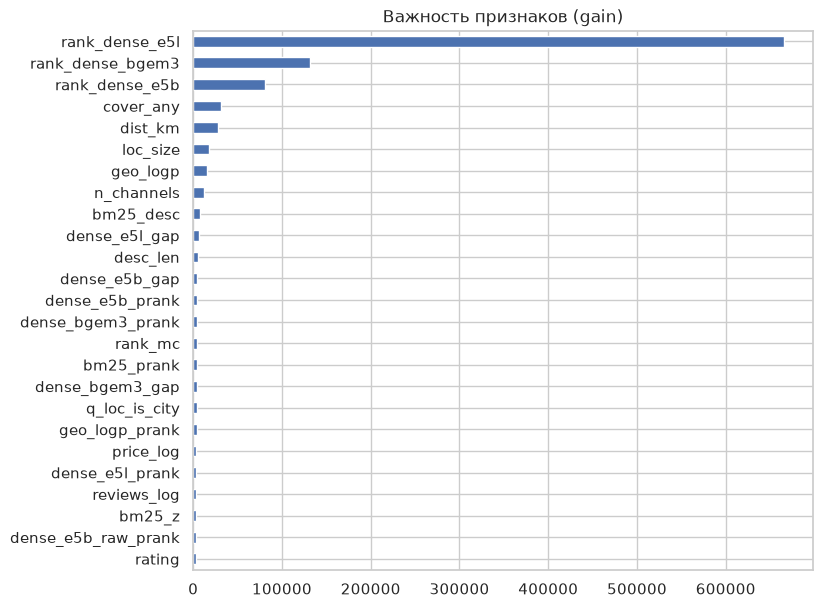

In [8]:
# Важность признаков (gain) финальной модели
model, cols = fit_ranker(pool_val, best_iter)
imp = pd.Series(model.feature_importance('gain'), index=cols).sort_values(ascending=False)
imp.head(25)[::-1].plot.barh(figsize=(8, 7), title='Важность признаков (gain)'); plt.show()

## 4. Ответ на бенчмарк

Финальный ранжировщик — среднее 5 моделей LightGBM с разными seed (стабильнее одной),
обученных на всех отложенных поисках. Проверяем формат по требованиям задания и сохраняем `answer.csv`.

In [9]:
score = np.zeros(len(pool_bench))
for seed in range(5):
    m, cols = fit_ranker(pool_val, best_iter, seed=seed)
    s = m.predict(pool_bench[cols])
    score += (s - s.mean()) / (s.std() + 1e-9)
pool_bench[['q_row', 'item_id']].assign(pred=score).to_parquet(ART / 'stage1_bench.parquet')   # для реранкера (05)
answer = make_answer(pool_bench, q_bench, score, k=50)
check_answer(answer, q_bench, corpus.loc[corpus['in_bench'] == 1, 'item_id'])
answer.to_csv('../answer.csv', index=False)
print('answer.csv:', answer.shape, '| id в строке:', answer['answer'].str.split().str.len().describe()[['min', 'mean', 'max']].to_dict())
answer.head(3)

answer.csv: (2452, 2) | id в строке: {'min': 50.0, 'mean': 50.0, 'max': 50.0}


,query_id,answer
0,70DfDUpwjxB4lzFd,b92ee8f432cec2d1 355392014208b7bf d722bcda1a55...
1,JTrdTaZJvSiLPkXj,422d3ffdd5bbf626 cbeccbecb1fb8d86 367af128a9ea...
2,LZCZNoVG4AFUkVRJ,dab52187b4500d9b d8fce513e4f000a7 168a9207e80b...
